# Tabular Data Classification — Diabetes 130-US Hospitals

Hospital **readmissions** are an important consideration in discharge planning and continuity of care. This experiment examines whether information recorded during a hospital encounter can help identify patients who are readmitted within 30 days of discharge.

The analysis uses the **UCI Diabetes 130-US Hospitals** dataset, which contains encounters from 130 hospitals and integrated delivery networks between 1999 and 2008. Each row represents a hospital stay, with features covering patient characteristics, diagnoses, treatments, and prior use of care. This is a **tabular classification** task: a model uses the features in each row to predict a category. Here, the two categories are readmission within 30 days and no recorded readmission within that period.

We use **FG Data Profiling** for exploratory analysis, pandas and scikit-learn for data preparation and evaluation, **CatBoost** and **TabPFN** for classification, **Optuna** for CatBoost tuning, and **MLflow** for experiment tracking. We evaluate both models on held-out patients and use **SHAP** to examine the features influencing their predictions.


### Installation

Install the libraries needed for data preparation, analysis, model training, and experiment tracking.


In [1]:
import sys
!uv pip install --python "{sys.executable}" -q ucimlrepo fg-data-profiling scikit-learn mlflow optuna matplotlib shap catboost python-dotenv tabpfn 'tabpfn-extensions[interpretability]'
%matplotlib inline

### Dataset Loading

Load the UCI Diabetes 130-US Hospitals dataset (ID 296), including its features, target, and metadata.


In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
diabetes_hospital_dataset = fetch_ucirepo(id=296)

# data (as pandas dataframes)
X = diabetes_hospital_dataset.data.features
y = diabetes_hospital_dataset.data.targets["readmitted"].copy()

# metadata
print(diabetes_hospital_dataset.metadata)

# variable information
print(diabetes_hospital_dataset.variables)

{'uci_id': 296, 'name': 'Diabetes 130-US Hospitals for Years 1999-2008', 'repository_url': 'https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008', 'data_url': 'https://archive.ics.uci.edu/static/public/296/data.csv', 'abstract': 'The dataset represents ten years (1999-2008) of clinical care at 130 US hospitals and integrated delivery networks. Each row concerns hospital records of patients diagnosed with diabetes, who underwent laboratory, medications, and stayed up to 14 days. The goal is to determine the early readmission of the patient within 30 days of discharge.\nThe problem is important for the following reasons. Despite high-quality evidence showing improved clinical outcomes for diabetic patients who receive various preventive and therapeutic interventions, many patients do not receive them. This can be partially attributed to arbitrary diabetes management in hospital environments, which fail to attend to glycemic control. Failure to provide pro

/home/anil/miniconda3/envs/tab/lib/python3.14/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


### Binary Target Conversion

Convert the target into two classes: `Readmitted <30` and `Not <30`.


In [3]:
# Keep early readmission separate and combine the other outcomes.
y = y.map({"<30": "Readmitted <30", ">30": "Not <30", "NO": "Not <30"})
assert y.notna().all(), "Unexpected or missing readmission labels"
print(y.value_counts())

readmitted
Not <30           90409
Readmitted <30    11357
Name: count, dtype: int64


**Note:** We combine the other outcomes because this experiment focuses on whether readmission occurred within 30 days.


### Dataset Overview

Inspect dataset dimensions, sample records, feature types, and the target distribution.


In [4]:
# Basic overview
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 rows:")
print(X.head())

print("\nColumn information:")
X.info()

print("\nTarget distribution:")
print(y.value_counts(dropna=False))

print("\nFeature statistics:")
display(X.describe(include="all").T)

Features shape: (101766, 47)
Target shape: (101766,)

First 5 rows:
              race  gender      age weight  admission_type_id  \
0        Caucasian  Female   [0-10)    NaN                  6   
1        Caucasian  Female  [10-20)    NaN                  1   
2  AfricanAmerican  Female  [20-30)    NaN                  1   
3        Caucasian    Male  [30-40)    NaN                  1   
4        Caucasian    Male  [40-50)    NaN                  1   

   discharge_disposition_id  admission_source_id  time_in_hospital payer_code  \
0                        25                    1                 1        NaN   
1                         1                    7                 3        NaN   
2                         1                    7                 2        NaN   
3                         1                    7                 2        NaN   
4                         1                    7                 1        NaN   

          medical_specialty  ...  examide  citoglipton

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
race,99493,5,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,3197,9,[75-100),1336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
payer_code,61510,17,MC,32439,NaN,NaN,NaN,NaN,NaN,NaN,NaN
medical_specialty,51817,72,InternalMedicine,14635,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing Value Standardization

- Convert `"?"` to `NaN`.
- Preserve `"None"` in `A1Cresult` and `max_glu_serum` as the category for tests not performed.


In [5]:
import numpy as np

# Standardize missing-value markers
X = X.replace("?", np.nan)

# Restore valid test-not-performed categories
X["A1Cresult"] = X["A1Cresult"].fillna("None")
X["max_glu_serum"] = X["max_glu_serum"].fillna("None")

### Exploratory Data Analysis (EDA)

Generate a profiling report for the full dataset to inspect distributions, missing values, correlations, and data-quality issues.


In [6]:
import numpy as np
import pandas as pd
from data_profiling import ProfileReport

df = pd.concat([X, y], axis=1)

# Generate EDA report
profile = ProfileReport(
    df,
    title="Diabetes Dataset Analysis",
    explorative=True,
)

profile.to_file("diabetes_hospital_report.html")

/home/anil/miniconda3/envs/tab/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Export report to file: 100%|██████████| 1/1 [00:00<00:00, 90.32it/s]


### Feature Selection and Type Conversion

- Exclude hospice and expired discharges (disposition IDs 11, 13, 14, 19, 20, and 21).
- Identify numerical features using the UCI metadata and treat the remaining features as categorical.
- Remove `weight` (approximately 97% missing) and the constant features `examide` and `citoglipton`.
- Convert categorical features to pandas `category` dtype.


In [7]:
# Exclude expired and hospice discharges from the readmission-risk cohort
excluded_dispositions = {11, 13, 14, 19, 20, 21}
eligible = ~pd.to_numeric(X["discharge_disposition_id"], errors="coerce").isin(excluded_dispositions)
print(f"Excluded encounters: {(~eligible).sum():,}")
X = X.loc[eligible].copy()
y = y.loc[eligible].copy()

# Select numerical features from official UCI metadata
numerical_cols = diabetes_hospital_dataset.variables.loc[
    (diabetes_hospital_dataset.variables["role"] == "Feature")
    & (diabetes_hospital_dataset.variables["type"] == "Integer"),
    "name",
].tolist()

# Remove unnecessary columns
X = X.drop(
    columns=["weight", "examide", "citoglipton"],
)

# Remaining columns are categorical
categorical_cols = [
    col for col in X.columns
    if col not in numerical_cols
]

# Convert categorical columns
X[categorical_cols] = X[categorical_cols].astype("category")


# Verify the feature types after selection.
print("Numerical:", X.select_dtypes(include="number").shape[1])
print("Categorical:", X.select_dtypes(include="category").shape[1])
print("Total:", X.shape[1])

Excluded encounters: 2,423
Numerical: 8
Categorical: 36
Total: 44


### Train/Test Split

Hold out one of seven patient-grouped folds for testing and use the rest for development. No patient appears in both sets.


In [8]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder

SEED = 42
N_TRIALS = 25

# Align patient IDs with the filtered cohort and reserve one grouped fold
# for final testing. A patient cannot appear in both development and test.
groups = diabetes_hospital_dataset.data.ids.loc[X.index, "patient_nbr"]
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)

dev_idx, test_idx = next(splitter.split(X, y, groups))
X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev = groups.iloc[dev_idx]

# Fit the label mapping on development data, then reuse it for the test set.
label_encoder = LabelEncoder().fit(y_dev)
y_dev_encoded = label_encoder.transform(y_dev)
y_test_encoded = label_encoder.transform(y_test)

# Reuse the same patient-grouped folds for every baseline and Optuna trial.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_dev, y_dev_encoded, groups_dev))
print(f"Development: {len(X_dev):,}; test: {len(X_test):,}")
print("Classes:", dict(enumerate(label_encoder.classes_)))


Development: 85,151; test: 14,192
Classes: {0: 'Not <30', 1: 'Readmitted <30'}


### Hyperparameter Tuning

CatBoost is a useful starting point for this dataset because it handles categorical features directly and supports missing numerical values. We represent missing categorical values as a separate category before fitting.

- Score each Optuna trial by mean macro-F1 across three patient-grouped development folds.
- Use a fixed number of trees and calculate class weights from each training fold.
- Log each trial as a nested MLflow run, following the [MLflow tuning guide](https://mlflow.org/docs/latest/ml/getting-started/hyperparameter-tuning/).


In [9]:
import mlflow
import optuna
from catboost import CatBoostClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

mlflow.set_experiment("Diabetes Readmission Binary")

# CatBoost requires categorical values, including missing values, to be strings.
def prepare_catboost_features(X, categorical_columns):
    result = X.copy()
    for col in categorical_columns:
        result[col] = result[col].astype("string").fillna("__missing__").astype(object)
    return result

# Keep the tree count fixed so validation folds are used only for scoring.
def make_catboost_pipeline(params):
    return Pipeline([
        ("prepare", FunctionTransformer(prepare_catboost_features, kw_args={"categorical_columns": categorical_cols}, validate=False)),
        ("model", CatBoostClassifier(
            **params, iterations=500, cat_features=categorical_cols,
            random_seed=SEED, task_type="GPU", verbose=False,
            allow_writing_files=False, auto_class_weights="Balanced",
        )),
    ])

def train_and_score_cv(params=None):
    scores = []
    for train_idx, valid_idx in cv_splits:
        X_train, X_valid = X_dev.iloc[train_idx], X_dev.iloc[valid_idx]
        y_train, y_valid = y_dev_encoded[train_idx], y_dev_encoded[valid_idx]
        # The baseline predicts the majority class in each training fold.
        model = DummyClassifier(strategy="most_frequent") if params is None else make_catboost_pipeline(params)
        model.fit(X_train, y_train)
        predictions = np.asarray(model.predict(X_valid)).ravel()
        scores.append(f1_score(y_valid, predictions, average="macro", zero_division=0))
    return scores

def objective(trial):
    params = {
        "depth": trial.suggest_int("depth", 3, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 10.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.1, 5.0, log=True),
    }
    # Group trial parameters and fold scores under the study parent run.
    with mlflow.start_run(run_name=f"trial_{trial.number}", nested=True) as run:
        mlflow.log_params(params)
        scores = train_and_score_cv(params)
        mlflow.log_metrics({f"fold_{i}_macro_f1": score for i, score in enumerate(scores, 1)})
        mlflow.log_metric("mean_macro_f1", float(np.mean(scores)))
        trial.set_user_attr("run_id", run.info.run_id)
    return float(np.mean(scores))


2026/11/19 11:51:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/19 11:51:18 INFO mlflow.store.db.utils: Updating database tables
2026/11/19 11:51:19 INFO mlflow.tracking.fluent: Experiment with name 'Diabetes Readmission Binary' does not exist. Creating a new experiment.


**Note:** Early readmissions are less common than the other outcome. CatBoost uses balanced class weights to give them more influence during training.


### Model Selection

We start with a majority-class baseline that always predicts the most common outcome. It provides a reference point for assessing the model.

Optuna tests CatBoost settings using patient-grouped cross-validation. We select the trial with the highest average macro-F1, which gives equal weight to the F1 score of each class.


In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, log_loss

with mlflow.start_run(run_name="readmission_study") as run:
    mlflow.log_params({"iterations": 500, "n_trials": N_TRIALS, "cv_folds": len(cv_splits), "auto_class_weights": "Balanced", "device": "gpu"})

    # Evaluate the majority-class baseline on the development folds.
    majority_scores = train_and_score_cv()
    mlflow.log_metric("majority_cv_macro_f1", float(np.mean(majority_scores)))

    # Optimize mean macro-F1 across folds and record the best trial.
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_param("best_child_run_id", study.best_trial.user_attrs["run_id"])
    mlflow.log_metric("best_cv_macro_f1", study.best_value)

    print(f"Majority baseline CV macro-F1: {np.mean(majority_scores):.4f}")
    print(f"Best CV macro-F1: {study.best_value:.4f}")


[I 2026-11-19 11:51:29,542] A new study created in memory with name: no-name-b02e9434-7a3c-4b38-8969-98aa9e4bb6c7
[I 2026-11-19 11:51:49,336] Trial 0 finished with value: 0.5329346715161303 and parameters: {'depth': 4, 'learning_rate': 0.13125830316209655, 'l2_leaf_reg': 2.9106359131330697, 'random_strength': 1.0401663679887312}. Best is trial 0 with value: 0.5329346715161303.
[I 2026-11-19 11:52:01,824] Trial 1 finished with value: 0.5247550454390596 and parameters: {'depth': 3, 'learning_rate': 0.015256811898068502, 'l2_leaf_reg': 0.13066739238053282, 'random_strength': 2.962151658830348}. Best is trial 0 with value: 0.5329346715161303.
[I 2026-11-19 11:52:26,393] Trial 2 finished with value: 0.539337605089305 and parameters: {'depth': 6, 'learning_rate': 0.06803900745073706, 'l2_leaf_reg': 0.10994335574766201, 'random_strength': 4.44475416669081}. Best is trial 2 with value: 0.539337605089305.
[I 2026-11-19 11:52:56,748] Trial 3 finished with value: 0.5330124414655126 and parameters

Majority baseline CV macro-F1: 0.4698
Best CV macro-F1: 0.5540


**Note:** The majority-class baseline is not tuned; it is used for comparison.


### Test Evaluation

Refit the selected weighted model on all development data. Evaluate it on the held-out test set and log the model, metrics, classification report, and confusion matrix to MLflow.


2026/11/19 12:02:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


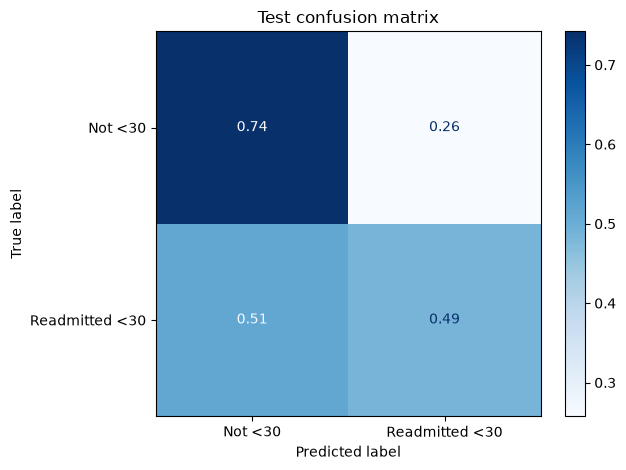

                precision    recall  f1-score   support

       Not <30       0.92      0.74      0.82     12576
Readmitted <30       0.19      0.49      0.28      1616

      accuracy                           0.71     14192
     macro avg       0.56      0.61      0.55     14192
  weighted avg       0.84      0.71      0.76     14192

Test macro-F1: 0.5495
Test log loss: 0.5664
MLflow run ID: b1f0031571eb4865ae6d34aecca57869


In [11]:
from IPython.display import display

with mlflow.start_run(run_id=run.info.run_id):
    # 1. Train the selected model on all development data.
    model = make_catboost_pipeline(study.best_params)
    model.fit(X_dev, y_dev_encoded)

    # 2. Evaluate the model on the held-out test set.
    predictions = np.asarray(model.predict(X_test)).ravel()
    probabilities = model.predict_proba(X_test)
    report = classification_report(y_test_encoded, predictions, target_names=label_encoder.classes_, output_dict=True, zero_division=0)
    test_log_loss = log_loss(y_test_encoded, probabilities, labels=model.classes_)

    # 3. Log the results, class mapping, and model to MLflow.
    mlflow.log_metrics({"test_macro_f1": report["macro avg"]["f1-score"], "test_log_loss": test_log_loss})
    mlflow.log_dict(report, "test_classification_report.json")
    mlflow.log_dict({str(i): label for i, label in enumerate(label_encoder.classes_)}, "class_mapping.json")
    logged_model = mlflow.sklearn.log_model(model, name="model", serialization_format="cloudpickle")

    # 4. Display the test confusion matrix and classification report.
    confusion_display = ConfusionMatrixDisplay.from_predictions(y_test_encoded, predictions, labels=model.classes_, display_labels=label_encoder.classes_, normalize="true", cmap="Blues", values_format=".2f")
    confusion_display.ax_.set_title("Test confusion matrix")
    confusion_display.figure_.tight_layout()
    mlflow.log_figure(confusion_display.figure_, "test_confusion_matrix.png")
    display(confusion_display.figure_)
    plt.close(confusion_display.figure_)

    print(classification_report(y_test_encoded, predictions, target_names=label_encoder.classes_, zero_division=0))
    print(f"Test macro-F1: {report['macro avg']['f1-score']:.4f}")
    print(f"Test log loss: {test_log_loss:.4f}")
    print(f"MLflow run ID: {run.info.run_id}")


### Precision–Recall and ROC Curves

These curves help us understand how well the model distinguishes the two outcomes and how its predictions change at different thresholds.

- **Precision–recall curve:** Shows the tradeoff between the proportion of flagged cases that are correct (precision) and the proportion of actual cases found (recall) as the threshold changes. The x-axis shows recall, and the y-axis shows precision.
- **ROC curve:** Shows the tradeoff between the proportion of actual cases found and the proportion of other cases incorrectly flagged as the threshold changes. The x-axis shows the false-positive rate, and the y-axis shows the true-positive rate (recall).
- Each class is compared with the other on the test set. Choose any decision threshold using development data.


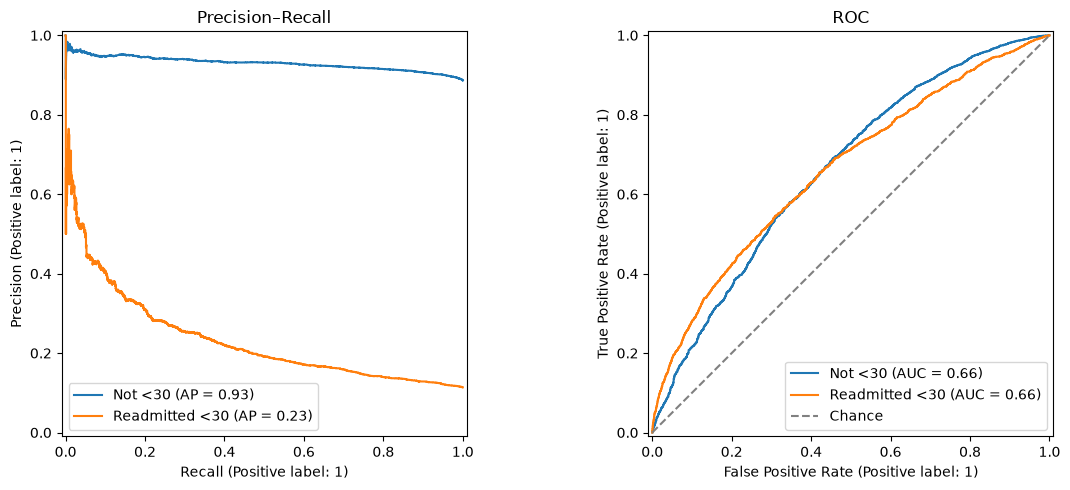

In [12]:
from IPython.display import display

from sklearn.metrics import (
    PrecisionRecallDisplay, RocCurveDisplay, average_precision_score, roc_auc_score,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
curve_metrics = {}

# Treat each class as positive in turn, using its predicted probability.
for class_id, class_name in enumerate(label_encoder.classes_):
    y_binary = (y_test_encoded == class_id).astype(int)
    probability = probabilities[:, np.flatnonzero(model.classes_ == class_id)[0]]

    average_precision = average_precision_score(y_binary, probability)
    roc_auc = roc_auc_score(y_binary, probability)

    PrecisionRecallDisplay.from_predictions(y_binary, probability, ax=axes[0], name=class_name)
    RocCurveDisplay.from_predictions(y_binary, probability, ax=axes[1], name=class_name)
    
    metric_class = {"Readmitted <30": "under_30", "Not <30": "not_under_30"}[class_name]
    curve_metrics[f"test_{metric_class}_average_precision"] = average_precision
    curve_metrics[f"test_{metric_class}_roc_auc"] = roc_auc

axes[0].set_title("Precision–Recall")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Chance")
axes[1].set_title("ROC")
axes[1].legend()
fig.tight_layout()

# Log the held-out scores and curves with the study run.
with mlflow.start_run(run_id=run.info.run_id):
    mlflow.log_metrics(curve_metrics)
    mlflow.log_figure(fig, "test_class_curves.png")
display(fig)
plt.close(fig)


#### Observations

- For early readmission, average precision is **0.24**, above the test-set rate of about **0.11**, though identifying these cases remains challenging.
- As the model finds more early readmissions, precision generally falls, so a larger share of flagged encounters are not early readmissions.
- The ROC-AUC is **0.67**, indicating some separation between early-readmission and other encounters, with considerable overlap.
- Average precision for `Not <30` is **0.93**. This class is much more common, so its score should be considered alongside its test-set rate of about **0.89**.


### Model Explanations

Model explainability helps us understand how features influence predictions. SHAP estimates each feature’s contribution, both for individual encounters and across a sample.

Here, we use SHAP to explore the model’s `<30` score. Select development or test data below; use test explanations only after model decisions are complete. The explanations use raw model scores, not probability changes, and do not establish causation.


In [13]:
import shap
from IPython.display import display

def explain_early_readmission(model, sample, label_encoder):
    # Explain the CatBoost model using the pipeline's prepared features.
    prepared = model.named_steps["prepare"].transform(sample)
    values = shap.TreeExplainer(model.named_steps["model"])(prepared)
    # Binary CatBoost explains the positive class; verify it is early readmission.
    assert label_encoder.transform(["Readmitted <30"])[0] == 1
    return values

def log_shap_plot(fig, dataset, name):
    fig.tight_layout()
    with mlflow.start_run(run_id=run.info.run_id):
        mlflow.log_figure(fig, f"shap/{dataset}/{name}.png")
    display(fig)
    plt.close(fig)


def plot_shap_importance(explanation, dataset):
    shap.plots.bar(explanation, max_display=15, show=False)
    log_shap_plot(plt.gcf(), dataset, "feature_importance")

def plot_shap_beeswarm(explanation, dataset):
    shap.plots.beeswarm(explanation, max_display=15, show=False)
    log_shap_plot(plt.gcf(), dataset, "beeswarm")

def plot_shap_waterfall(explanation, dataset, row=0):
    shap.plots.waterfall(explanation[row], max_display=15, show=False)
    log_shap_plot(plt.gcf(), dataset, f"waterfall_{row}")

def plot_shap_scatter(explanation, dataset, feature):
    shap.plots.scatter(explanation[:, feature], show=False)
    log_shap_plot(plt.gcf(), dataset, f"scatter_{feature}")

# Switch to "test" after finalizing the model.
SHAP_DATASET = "test"  # "development" or "test"
shap_data = {"development": X_dev, "test": X_test}[SHAP_DATASET]
shap_sample = shap_data.sample(n=min(500, len(shap_data)), random_state=SEED)
early_shap = explain_early_readmission(model, shap_sample, label_encoder)


#### SHAP Feature Importance

Rank features by their average contribution to the `<30` score across the sample. The chart shows contribution size, not whether a feature raises or lowers the score.


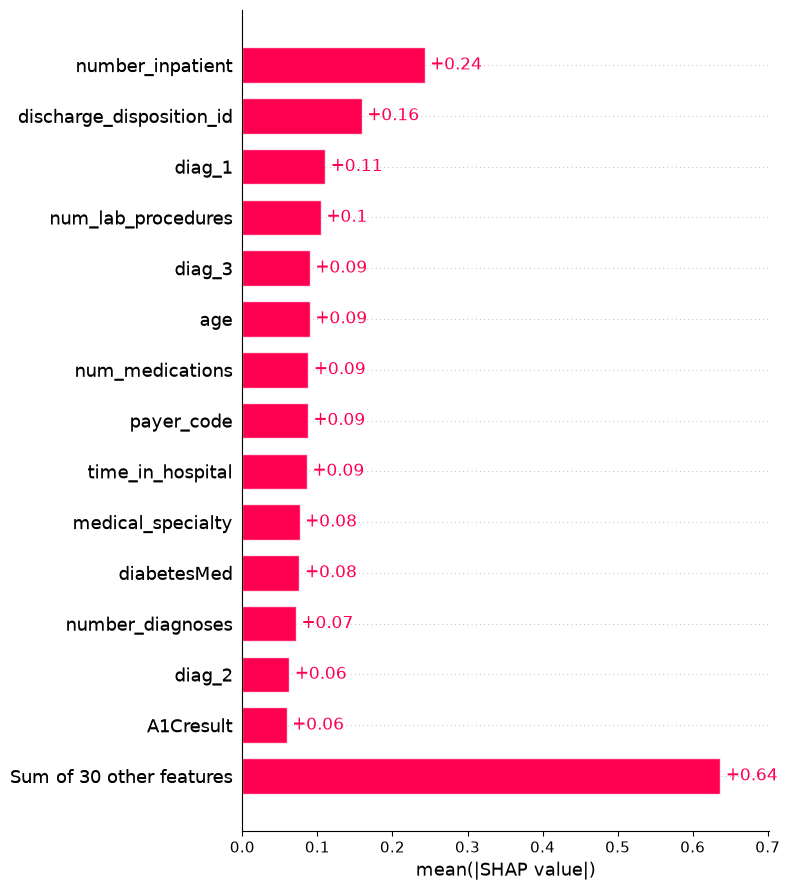

In [14]:
plot_shap_importance(early_shap, SHAP_DATASET)


#### SHAP Beeswarm

Show how each feature's contribution to the `<30` score varies across encounters. Points to the right raise the score; points to the left lower it. Colours show feature values where available.


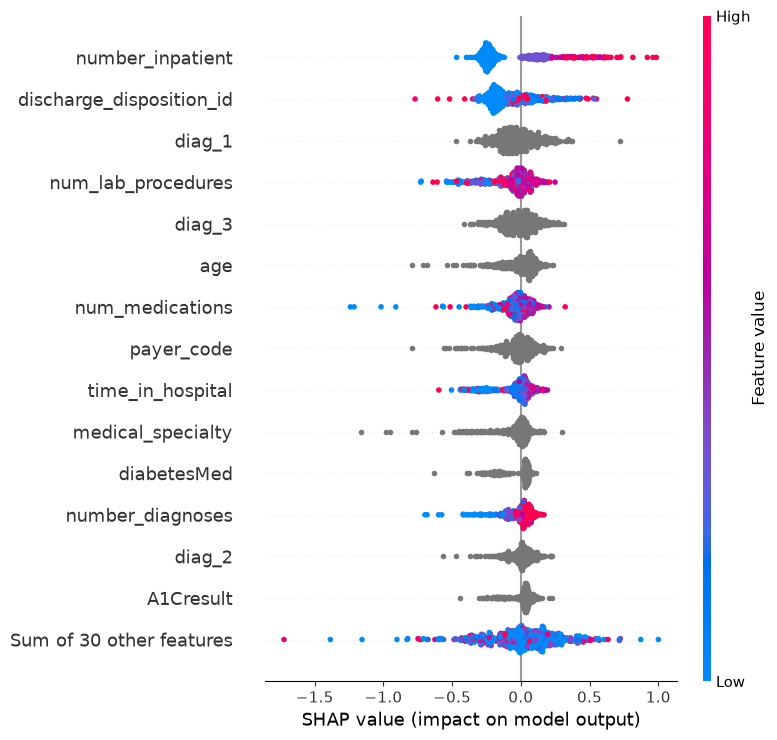

In [15]:
plot_shap_beeswarm(early_shap, SHAP_DATASET)


#### SHAP Waterfall

Explain one sampled encounter by showing how its features move the `<30` score from the model's baseline to its final score.


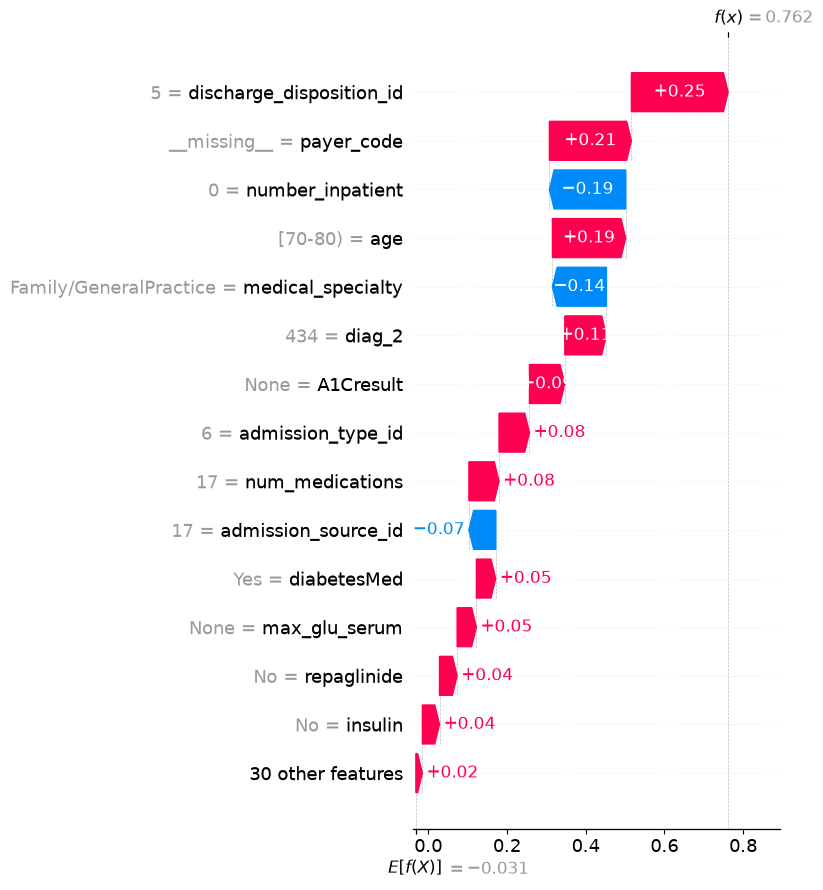

In [16]:
plot_shap_waterfall(early_shap, SHAP_DATASET, row=0)


#### SHAP Scatter Plot

Examine how the contribution of previous inpatient visits to the early-readmission score varies with the number of visits. Each point represents one encounter.


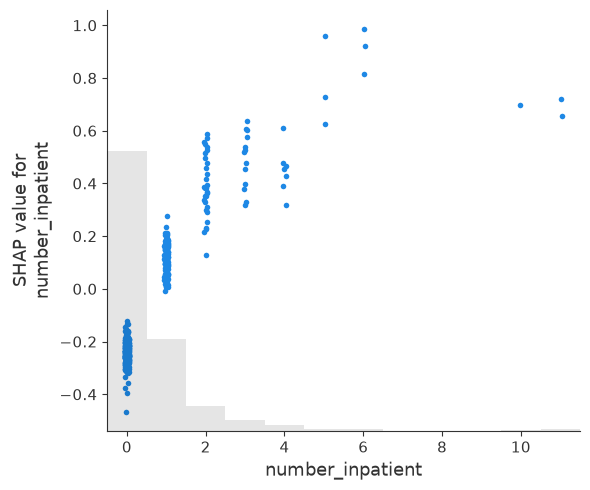

In [17]:
plot_shap_scatter(early_shap, SHAP_DATASET, feature="number_inpatient")


#### Observations


- **Previous inpatient visits** have the largest average influence among individual features in the sampled SHAP plot, followed by discharge destination. The **primary diagnosis and number of medications** also contribute.
- Encounters with more **previous inpatient visits** generally receive a higher early-readmission score from the model.
- Discharge destination and diagnosis effects vary by their recorded codes; the summary plots do not identify which codes consistently raise or lower the score.
- In the individual encounter shown, admission source, length of stay, and having no previous inpatient visits push the score down, while **discharge destination pushes it up**.
- These patterns describe the model’s predictions and do not establish what causes readmission.


### TabPFN 3.5

TabPFN 3.5 is a pretrained foundation model for tabular data. It uses labeled examples from this dataset as context for predictions. We evaluate it on one patient-grouped development split with probability balancing to account for the rarity of early readmissions. We then fit it on all development data and compare it with CatBoost on the same held-out patients.

The notebook downloads the weights from Hugging Face and runs predictions locally. On first use, sign in to Prior Labs and accept the license, which limits use to noncommercial, nonproduction purposes. [Model card and license](https://huggingface.co/Prior-Labs/tabpfn_3_5#licensing)


#### TabPFN Preparation

Reuse the existing features and target. TabPFN handles **categorical features and missing values** internally; probability balancing adjusts predictions for the class imbalance.


In [18]:
from importlib.metadata import version
from sklearn.metrics import average_precision_score, precision_score, recall_score
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

TABPFN_DEVICE = "cuda"  # Use "cpu" if no compatible GPU is available.

def score_tabpfn(estimator, X_eval, y_eval):
    # Predict in batches to reduce peak GPU memory use.
    probabilities = np.vstack([
        estimator.predict_proba(X_eval.iloc[i:i + 100])
        for i in range(0, len(X_eval), 100)
    ])
    classes = np.asarray(estimator.classes_)
    predictions = classes[np.argmax(probabilities, axis=1)]
    early_class = label_encoder.transform(["Readmitted <30"])[0]
    early_scores = probabilities[:, np.flatnonzero(classes == early_class)[0]]
    return {
        "macro_f1": f1_score(y_eval, predictions, average="macro", zero_division=0),
        "early_precision": precision_score(y_eval, predictions, pos_label=early_class, zero_division=0),
        "early_recall": recall_score(y_eval, predictions, pos_label=early_class, zero_division=0),
        "early_f1": f1_score(y_eval, predictions, pos_label=early_class, zero_division=0),
        "early_average_precision": average_precision_score((y_eval == early_class).astype(int), early_scores),
        "alert_rate": float(np.mean(predictions == early_class)),
    }


#### Development Evaluation

Evaluate TabPFN on one patient-grouped development split.


In [19]:
from dotenv import load_dotenv

load_dotenv()

# Use the first patient-grouped development split.
train_idx, valid_idx = cv_splits[0]
X_train, X_valid = X_dev.iloc[train_idx], X_dev.iloc[valid_idx]
y_train, y_valid = y_dev_encoded[train_idx], y_dev_encoded[valid_idx]

with mlflow.start_run(run_name="tabpfn_3_5") as tabpfn_run:
    mlflow.log_params({
        "tabpfn_model": "3.5", "tabpfn_package_version": version("tabpfn"),
        "tabpfn_device": TABPFN_DEVICE, "tabpfn_balance_probabilities": True,
        "tabpfn_n_estimators": "auto",
        "development_split": "patient_grouped_fold_1",
    })

    fold_model = TabPFNClassifier.create_default_for_version(ModelVersion.V3_5, device=TABPFN_DEVICE, random_state=SEED, fit_mode="fit_with_cache", balance_probabilities=True)
    fold_model.fit(X_train, y_train)
    tabpfn_valid = score_tabpfn(fold_model, X_valid, y_valid)
    mlflow.log_metrics({f"tabpfn_valid_{k}": v for k, v in tabpfn_valid.items()})
    del fold_model  # Free the development model before fitting the final model.

display(pd.DataFrame({"TabPFN 3.5": tabpfn_valid}).round(4))


,TabPFN 3.5
macro_f1,0.5229
early_precision,0.1851
early_recall,0.6350
early_f1,0.2866
early_average_precision,0.2553
alert_rate,0.3908


- Patient grouping keeps validation patients separate from training patients.
- Probability balancing accounts for class imbalance; predictions use the default decision threshold.


#### TabPFN Test Evaluation

Fit TabPFN on all development patients and evaluate it on the held-out test patients.

In [20]:
tabpfn_model = TabPFNClassifier.create_default_for_version(ModelVersion.V3_5, device=TABPFN_DEVICE, random_state=SEED, fit_mode="fit_with_cache", balance_probabilities=True)
tabpfn_model.fit(X_dev, y_dev_encoded)

tabpfn_test = score_tabpfn(tabpfn_model, X_test, y_test_encoded)
display(pd.DataFrame({"TabPFN 3.5": tabpfn_test}).round(4))

with mlflow.start_run(run_id=tabpfn_run.info.run_id):
    mlflow.log_metrics({f"tabpfn_test_{k}": v for k, v in tabpfn_test.items()})
    mlflow.log_dict(tabpfn_test, "test_metrics.json")
    mlflow.log_dict({str(i): label for i, label in enumerate(label_encoder.classes_)}, "class_mapping.json")

print(f"MLflow run ID: {tabpfn_run.info.run_id}")


,TabPFN 3.5
macro_f1,0.5233
early_precision,0.1845
early_recall,0.6256
early_f1,0.2849
early_average_precision,0.2696
alert_rate,0.3861


MLflow run ID: 746f38d211444f10805fff24fa2734fd


#### TabPFN Model Explanations

Use Prior Labs’ interpretability extension to estimate how features affect the model’s balanced `<30` score. Explain the same 500 encounters as CatBoost. These approximate explanations use one development encounter as a reference, so they differ from CatBoost’s raw-score explanations and do not establish causation.


In [ ]:
from tabpfn_extensions.interpretability import shapiq_to_shap_explanation
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer

# Reuse CatBoost's sample and choose a reproducible development reference.
TABPFN_SHAP_DATASET = SHAP_DATASET
tabpfn_shap_sample = shap_sample
tabpfn_shap_reference = X_dev.sample(n=1, random_state=SEED)
early_index = int(np.flatnonzero(tabpfn_model.classes_ == label_encoder.transform(["Readmitted <30"])[0])[0])

# Preserve feature types and explain the same balanced probabilities used in evaluation.
class TabPFNProbabilityModel:
    fit_mode = "fit_with_cache"

    def predict_proba(self, values):
        frame = pd.DataFrame(values, columns=X_dev.columns).astype(X_dev.dtypes.to_dict())
        return tabpfn_model.predict_proba(frame)

explainer = get_tabpfn_imputation_explainer(
    model=TabPFNProbabilityModel(), data=tabpfn_shap_reference, class_index=early_index,
    index="SV", max_order=1, random_state=SEED,
)
tabpfn_shap = shapiq_to_shap_explanation(
    explainer, tabpfn_shap_sample, budget=128, feature_names=list(X_dev.columns),
)

# Use the reference prediction as the baseline; the SHAP bridge may return zero.
reference_score = tabpfn_model.predict_proba(tabpfn_shap_reference)[0, early_index]
tabpfn_shap.base_values = np.full(len(tabpfn_shap_sample), reference_score)

# Check how closely the approximate contributions reconstruct model scores.
sample_scores = np.concatenate([
    tabpfn_model.predict_proba(tabpfn_shap_sample.iloc[i:i + 100])[:, early_index]
    for i in range(0, len(tabpfn_shap_sample), 100)
])
reconstructed_scores = tabpfn_shap.base_values + tabpfn_shap.values.sum(axis=1)
print(f"Reference score: {reference_score:.4f}")
print(f"Largest reconstruction difference: {np.max(np.abs(reconstructed_scores - sample_scores)):.6f}")

def show_tabpfn_shap(name):
    fig = plt.gcf()
    fig.tight_layout()
    with mlflow.start_run(run_id=tabpfn_run.info.run_id):
        mlflow.log_figure(fig, f"shap/{TABPFN_SHAP_DATASET}/{name}.png")
    display(fig)
    plt.close(fig)


##### SHAP Feature Importance

Rank features by their average contribution size to the `<30` score in the sample.


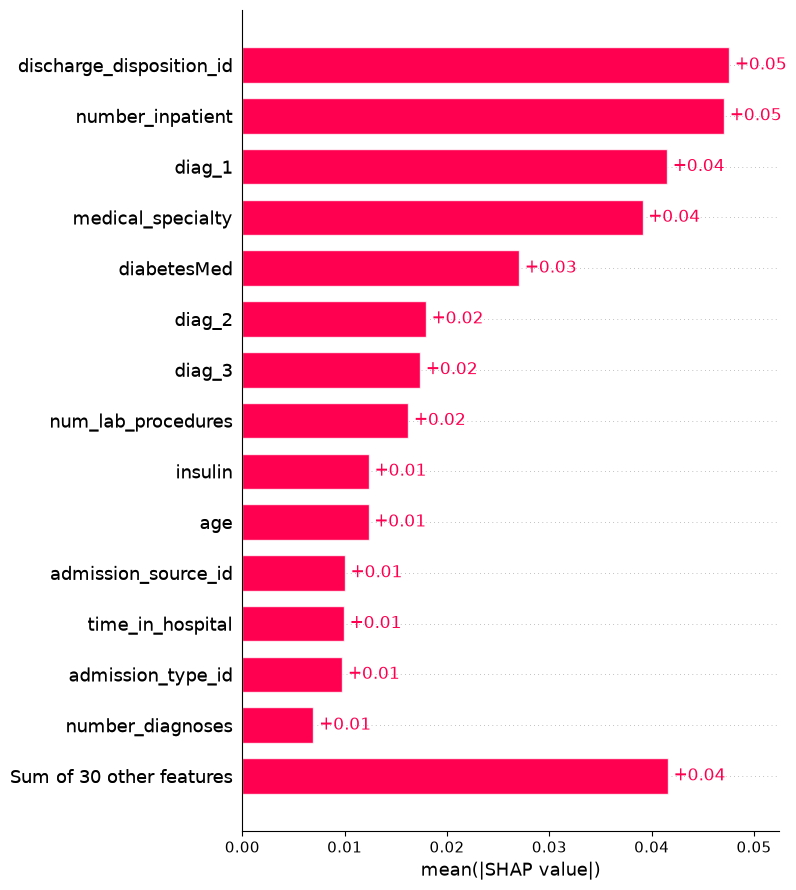

In [ ]:
shap.plots.bar(tabpfn_shap, max_display=15, show=False)
show_tabpfn_shap("feature_importance")


##### SHAP Beeswarm

Show how each feature’s contribution varies across sampled encounters. Points to the right raise the score relative to the reference; points to the left lower it.


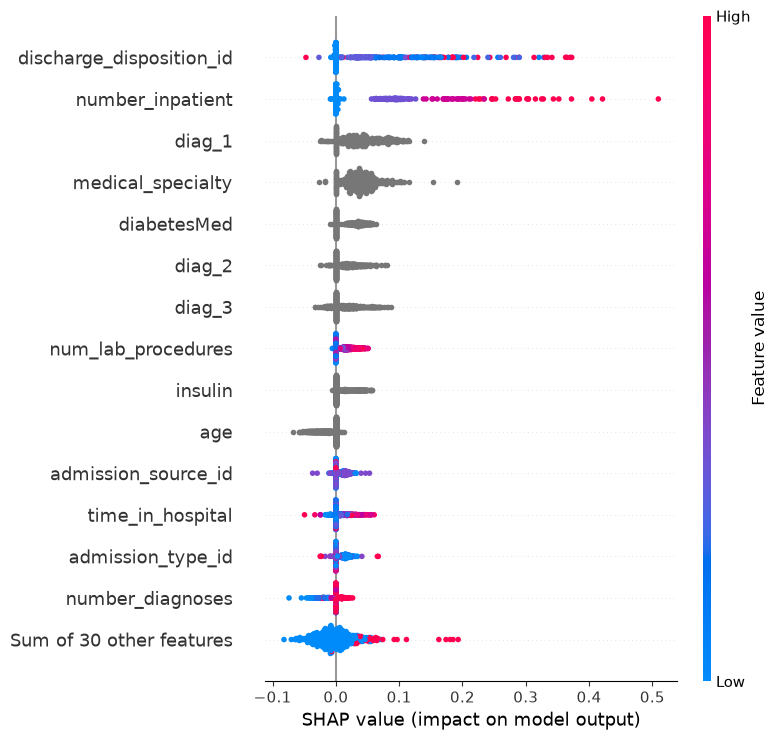

In [ ]:
shap.plots.beeswarm(tabpfn_shap, max_display=15, show=False)
show_tabpfn_shap("beeswarm")


##### SHAP Waterfall

Show how features move one encounter’s score from the reference score toward its prediction. The contributions are approximate.


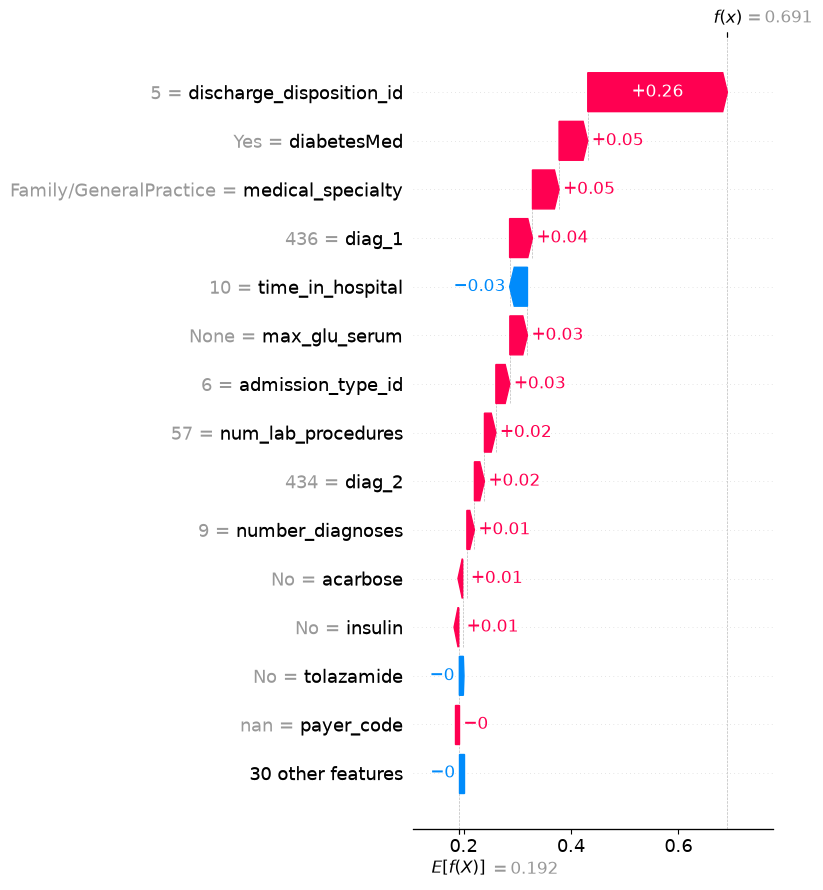

In [ ]:
shap.plots.waterfall(tabpfn_shap[0], max_display=15, show=False)
show_tabpfn_shap("waterfall_0")


##### SHAP Scatter Plot

Show how the contribution of previous inpatient visits varies with the number of visits in the sample.


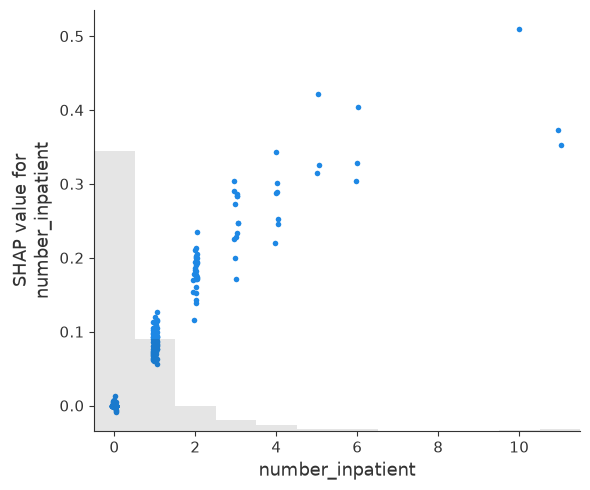

In [ ]:
shap.plots.scatter(tabpfn_shap[:, "number_inpatient"], show=False)
show_tabpfn_shap("scatter_number_inpatient")


##### Observations

- **Discharge destination** and **previous inpatient visits** have the largest average influence in the sampled plots, followed by primary diagnosis and medical specialty.
- Encounters with more **previous inpatient visits** generally receive a higher `<30` score relative to the reference encounter.
- The effects of discharge destination and diagnosis vary by their recorded codes; the summary plots do not identify which codes consistently raise or lower the score.
- For the encounter in the waterfall plot, **discharge destination** is the largest upward contribution. Diabetes medication, medical specialty, and primary diagnosis also raise the score relative to the reference.
- These approximate patterns describe this sample and reference; they do not establish what causes readmission.


### Model Comparison

| Metric | CatBoost | TabPFN |
| --- | ---: | ---: |
| Macro-F1 | 0.55 | 0.52 |
| `<30` precision | 0.19 | 0.18 |
| `<30` recall | 0.49 | 0.63 |
| `<30` F1 | 0.28 | 0.28 |

CatBoost has higher macro-F1, while TabPFN finds more early readmissions and raises alerts for about 39% of test encounters. This comparison is exploratory: the test set has already been inspected, and CatBoost was tuned across three development folds while TabPFN was evaluated on one split.


**Note**: To view runs, start `mlflow server --port 5000` in a separate terminal from the same working directory, then open http://localhost:5000. Configure the tracking URI before the study if using a remote server.


### Summary

- **Dataset:** The UCI Diabetes 130-US Hospitals dataset contains hospital encounters from **130 hospitals and integrated delivery networks** (1999–2008). We predict **readmission within 30 days**: `<30` is the positive class, while `>30` and `NO` are combined as `Not <30`.
- **Preparation:** We standardize `?` as missing while preserving `None` for tests that were not performed, exclude **hospice and expired discharges**, remove `weight` (about **97% missing**) and two constant features, and mark categorical columns for CatBoost.
- **Modeling:** A **patient-grouped split** holds out one of seven folds, keeping each patient’s visits together; three grouped folds are used for CatBoost tuning. We compare with a majority-class baseline, tune CatBoost using **class weights** and **Optuna** to maximize mean macro-F1, and log trials with **MLflow**; TabPFN uses probability balancing, is evaluated on one grouped development split, then fit on all development patients without Optuna tuning.
- **Test results:** On the held-out patients, CatBoost has higher **macro-F1** (**0.55 vs 0.52**). Both models have an `<30` **F1 of 0.28**; TabPFN has higher `<30` **recall** (**0.63 vs 0.49**) but low **precision** (**0.18 vs 0.19**), so about four in five TabPFN alerts are false positives. CatBoost’s `<30` average precision is **0.24** and ROC-AUC is **0.67**; because the test set has already been inspected and the models used different development evaluations, treat the comparison as exploratory.
- **Evaluation and explanations:** The **precision–recall curve** shows the precision/recall tradeoff, while the **ROC curve** shows separation across thresholds; the classification report and confusion matrix summarize test decisions. **SHAP** examines the same 500 test encounters: previous inpatient visits and discharge destination stand out for both models, though their ranking differs; SHAP contributions describe model behavior, not causes.
